In [2]:
pip install ucimlrepo

  Using cached ucimlrepo-0.0.7-py3-none-any.whl.metadata (5.5 kB)
Using cached ucimlrepo-0.0.7-py3-none-any.whl (8.0 kB)
Note: you may need to restart the kernel to use updated packages.


In [3]:
from ucimlrepo import fetch_ucirepo 
  
# fetch dataset 
online_retail = fetch_ucirepo(id=352) 
  
# data (as pandas dataframes) 
X = online_retail.data.features 
y = online_retail.data.targets 
  
# metadata 
print(online_retail.metadata) 
  
# variable information 
print(online_retail.variables) 

{'uci_id': 352, 'name': 'Online Retail', 'repository_url': 'https://archive.ics.uci.edu/dataset/352/online+retail', 'data_url': 'https://archive.ics.uci.edu/static/public/352/data.csv', 'abstract': 'This is a transactional data set which contains all the transactions occurring between 01/12/2010 and 09/12/2011 for a UK-based and registered non-store online retail.', 'area': 'Business', 'tasks': ['Classification', 'Clustering'], 'characteristics': ['Multivariate', 'Sequential', 'Time-Series'], 'num_instances': 541909, 'num_features': 6, 'feature_types': ['Integer', 'Real'], 'demographics': [], 'target_col': None, 'index_col': ['InvoiceNo', 'StockCode'], 'has_missing_values': 'no', 'missing_values_symbol': None, 'year_of_dataset_creation': 2015, 'last_updated': 'Mon Oct 21 2024', 'dataset_doi': '10.24432/C5BW33', 'creators': ['Daqing Chen'], 'intro_paper': {'ID': 361, 'type': 'NATIVE', 'title': 'Data mining for the online retail industry: A case study of RFM model-based customer segmenta

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans

sns.set_style("whitegrid")

In [5]:
from ucimlrepo import fetch_ucirepo

online_retail = fetch_ucirepo(id=352)
df = online_retail.data.features.copy()

df.head()
df.info()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 6 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   Description  540455 non-null  object 
 1   Quantity     541909 non-null  int64  
 2   InvoiceDate  541909 non-null  object 
 3   UnitPrice    541909 non-null  float64
 4   CustomerID   406829 non-null  float64
 5   Country      541909 non-null  object 
dtypes: float64(2), int64(1), object(3)
memory usage: 24.8+ MB


Description      1454
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     135080
Country             0
dtype: int64

In [6]:
online_retail.data

print(type(online_retail.data))

dir(online_retail.data)

online_retail.data.original.head()

<class 'ucimlrepo.dotdict.dotdict'>


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [8]:
df = online_retail.data.original.copy()

In [9]:
df = online_retail.data.original.copy()
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [12]:
df.info()
df.isnull().sum()

<class 'pandas.core.frame.DataFrame'>
Index: 406829 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   InvoiceNo    406829 non-null  object 
 1   StockCode    406829 non-null  object 
 2   Description  406829 non-null  object 
 3   Quantity     406829 non-null  int64  
 4   InvoiceDate  406829 non-null  object 
 5   UnitPrice    406829 non-null  float64
 6   CustomerID   406829 non-null  float64
 7   Country      406829 non-null  object 
dtypes: float64(2), int64(1), object(5)
memory usage: 27.9+ MB


InvoiceNo      0
StockCode      0
Description    0
Quantity       0
InvoiceDate    0
UnitPrice      0
CustomerID     0
Country        0
dtype: int64

In [13]:
df = df.dropna(subset=["CustomerID"])

In [14]:
df["InvoiceNo"] = df["InvoiceNo"].astype(str)
df = df[~df["InvoiceNo"].str.startswith("C")]

In [15]:
df = df[df["Quantity"] > 0]
df = df[df["UnitPrice"] > 0]

In [16]:
df.shape
df.head()

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [17]:
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])

In [18]:
df["InvoiceDate"].head()

0   2010-12-01 08:26:00
1   2010-12-01 08:26:00
2   2010-12-01 08:26:00
3   2010-12-01 08:26:00
4   2010-12-01 08:26:00
Name: InvoiceDate, dtype: datetime64[ns]

In [19]:
df["TotalPrice"] = df["Quantity"] * df["UnitPrice"]
df[["Quantity", "UnitPrice", "TotalPrice"]].head()

,Quantity,UnitPrice,TotalPrice
0,6,2.55,15.30
1,6,3.39,20.34
2,8,2.75,22.00
3,6,3.39,20.34
4,6,3.39,20.34


In [20]:
df.shape

(397884, 9)

In [21]:
df["InvoiceMonth"] = df["InvoiceDate"].dt.to_period("M")
df["InvoiceDay"] = df["InvoiceDate"].dt.date
df["DayName"] = df["InvoiceDate"].dt.day_name()

In [22]:
df[["InvoiceDate", "InvoiceMonth", "InvoiceDay", "DayName"]].head()

,InvoiceDate,InvoiceMonth,InvoiceDay,DayName
0,2010-12-01 08:26:00,2010-12,2010-12-01,Wednesday
1,2010-12-01 08:26:00,2010-12,2010-12-01,Wednesday
2,2010-12-01 08:26:00,2010-12,2010-12-01,Wednesday
3,2010-12-01 08:26:00,2010-12,2010-12-01,Wednesday
4,2010-12-01 08:26:00,2010-12,2010-12-01,Wednesday


In [23]:
monthly_sales = df.groupby("InvoiceMonth")["TotalPrice"].sum().reset_index()
monthly_sales["InvoiceMonth"] = monthly_sales["InvoiceMonth"].astype(str)

print(monthly_sales)

   InvoiceMonth   TotalPrice
0       2010-12   572713.890
1       2011-01   569445.040
2       2011-02   447137.350
3       2011-03   595500.760
4       2011-04   469200.361
5       2011-05   678594.560
6       2011-06   661213.690
7       2011-07   600091.011
8       2011-08   645343.900
9       2011-09   952838.382
10      2011-10  1039318.790
11      2011-11  1161817.380
12      2011-12   518192.790


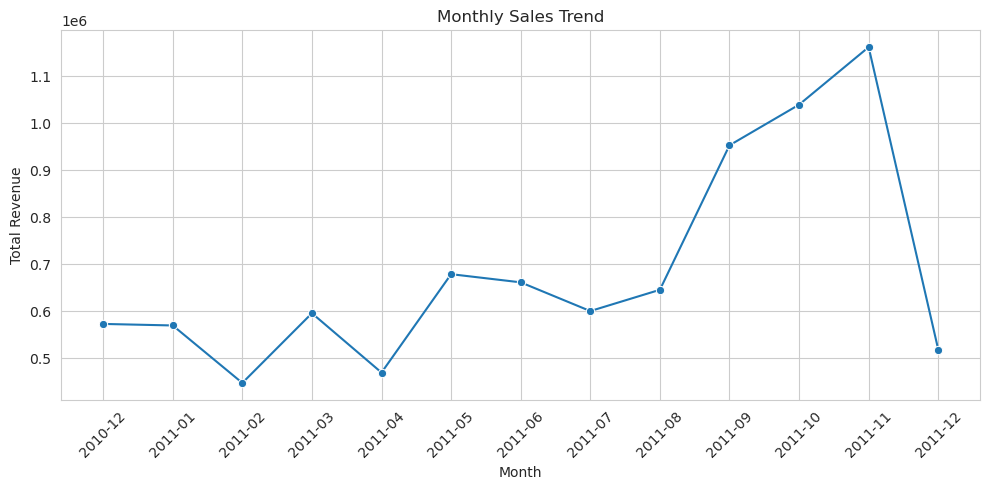

In [24]:
plt.figure(figsize=(10,5))
sns.lineplot(data=monthly_sales, x="InvoiceMonth", y="TotalPrice", marker="o")
plt.title("Monthly Sales Trend")
plt.xlabel("Month")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [25]:
daily_sales = df.groupby("InvoiceDay")["TotalPrice"].sum().reset_index()

print(daily_sales.head())

   InvoiceDay  TotalPrice
0  2010-12-01    46376.49
1  2010-12-02    47316.53
2  2010-12-03    23921.71
3  2010-12-05    31771.60
4  2010-12-06    31215.64


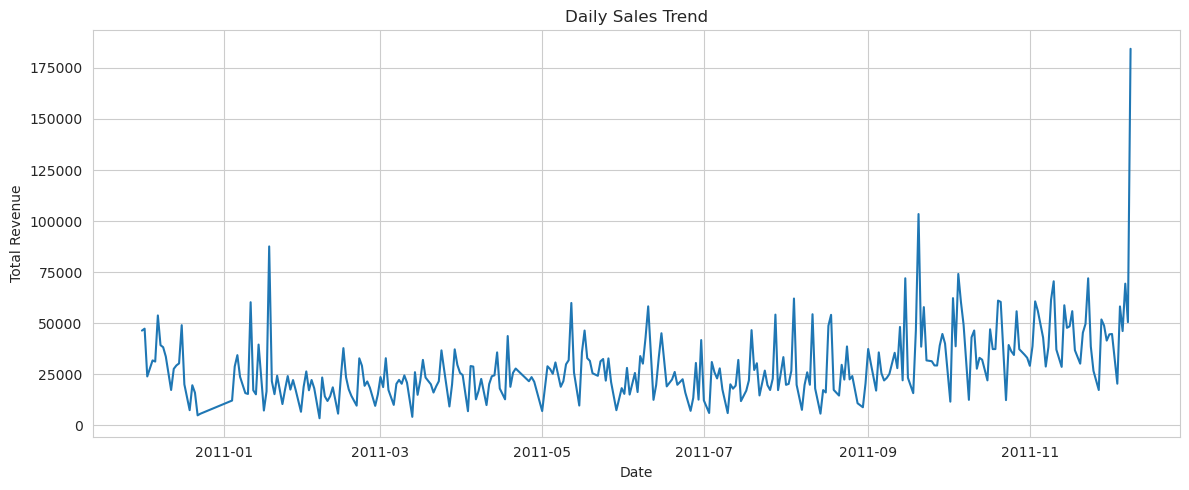

In [26]:
plt.figure(figsize=(12,5))
sns.lineplot(data=daily_sales, x="InvoiceDay", y="TotalPrice")
plt.title("Daily Sales Trend")
plt.xlabel("Date")
plt.ylabel("Total Revenue")
plt.tight_layout()
plt.show()

In [27]:
day_order = ["Monday", "Tuesday", "Wednesday", "Thursday", "Friday", "Saturday", "Sunday"]

sales_by_day = df.groupby("DayName")["TotalPrice"].sum().reindex(day_order).reset_index()

print(sales_by_day)

     DayName   TotalPrice
0     Monday  1367146.411
1    Tuesday  1700634.631
2  Wednesday  1588336.170
3   Thursday  1976859.070
4     Friday  1485917.401
5   Saturday          NaN
6     Sunday   792514.221


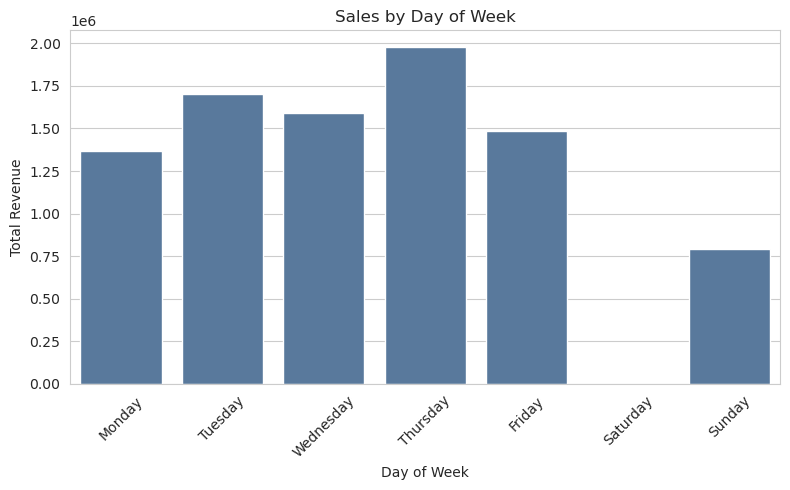

In [28]:
plt.figure(figsize=(8,5))
sns.barplot(data=sales_by_day, x="DayName", y="TotalPrice", color="#4E79A7")
plt.title("Sales by Day of Week")
plt.xlabel("Day of Week")
plt.ylabel("Total Revenue")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [29]:
top_month = monthly_sales.loc[monthly_sales["TotalPrice"].idxmax()]
print(top_month)

InvoiceMonth       2011-11
TotalPrice      1161817.38
Name: 11, dtype: object


In [30]:
top_day = daily_sales.loc[daily_sales["TotalPrice"].idxmax()]
print(top_day)

InvoiceDay    2011-12-09
TotalPrice     184349.28
Name: 304, dtype: object


In [31]:
top_weekday = sales_by_day.loc[sales_by_day["TotalPrice"].idxmax()]
print(top_weekday)

DayName         Thursday
TotalPrice    1976859.07
Name: 3, dtype: object
